In [1]:
import xarray as xr
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import verde as vd

import sys
sys.path.append("..")

import multipoles as mt
import micromag as mg
from micromag import MICROMETER_TO_METER, TESLA_TO_NANOTESLA

In [2]:
grid_dir = Path("../..") / "data/micromag_models/tecfiles/grids"
grid_files = sorted(grid_dir.glob("*.nc"))

Processing model: eps12 at height 0.05 µm


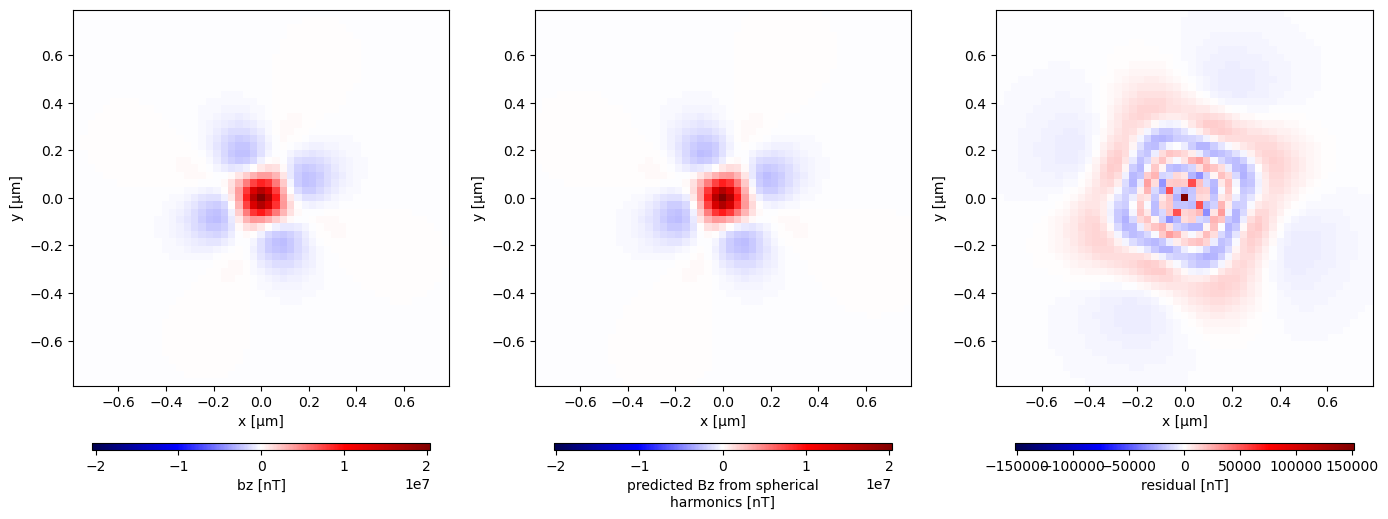

Processing model: eps12 at height 0.075 µm


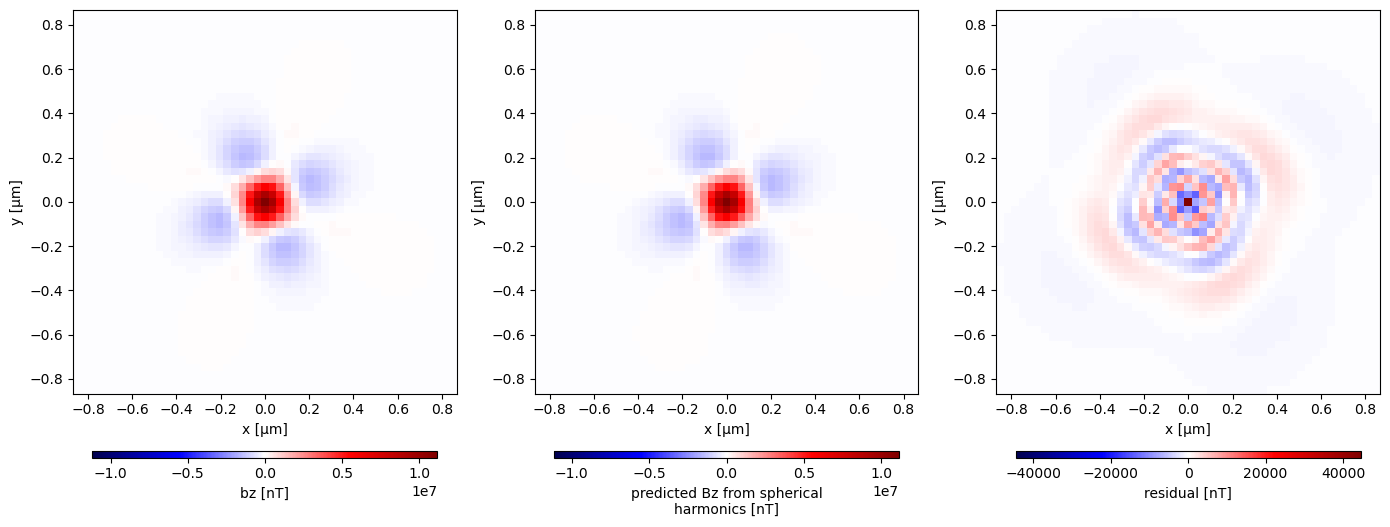

Processing model: eps12 at height 0.1 µm


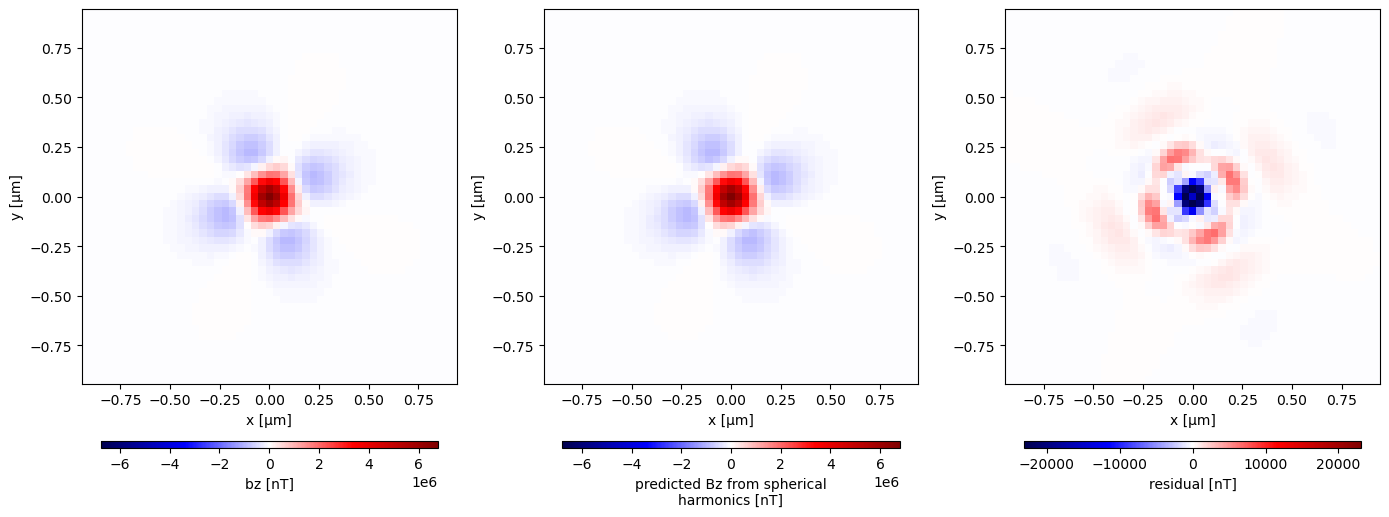

Processing model: eps12 at height 0.15 µm


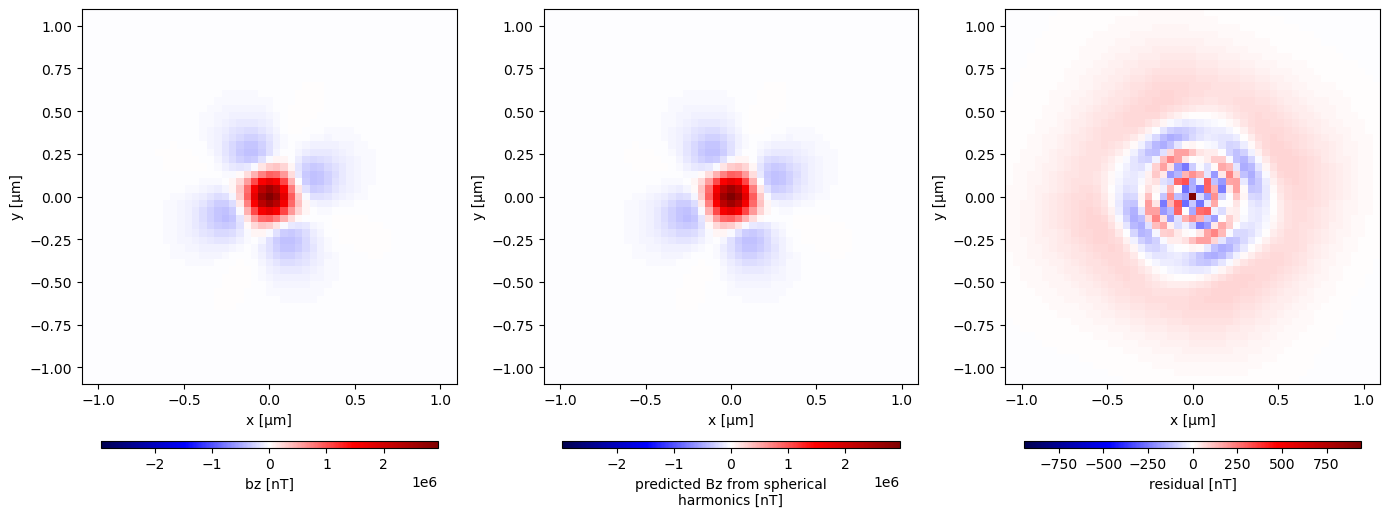

Processing model: eps12 at height 0.2 µm


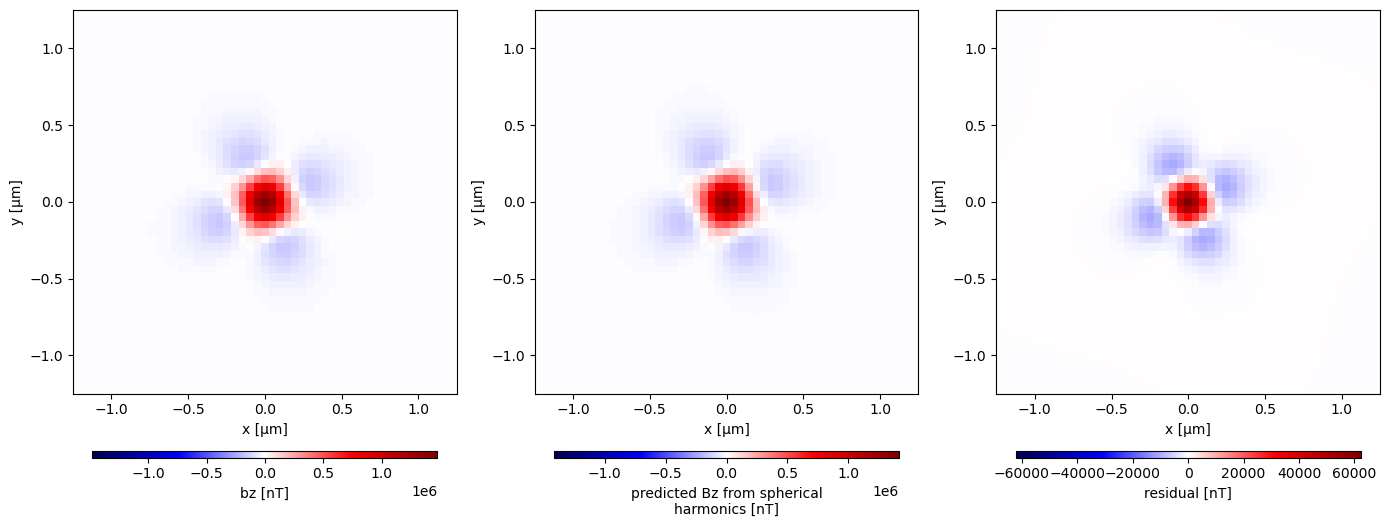

Processing model: eps12 at height 0.25 µm


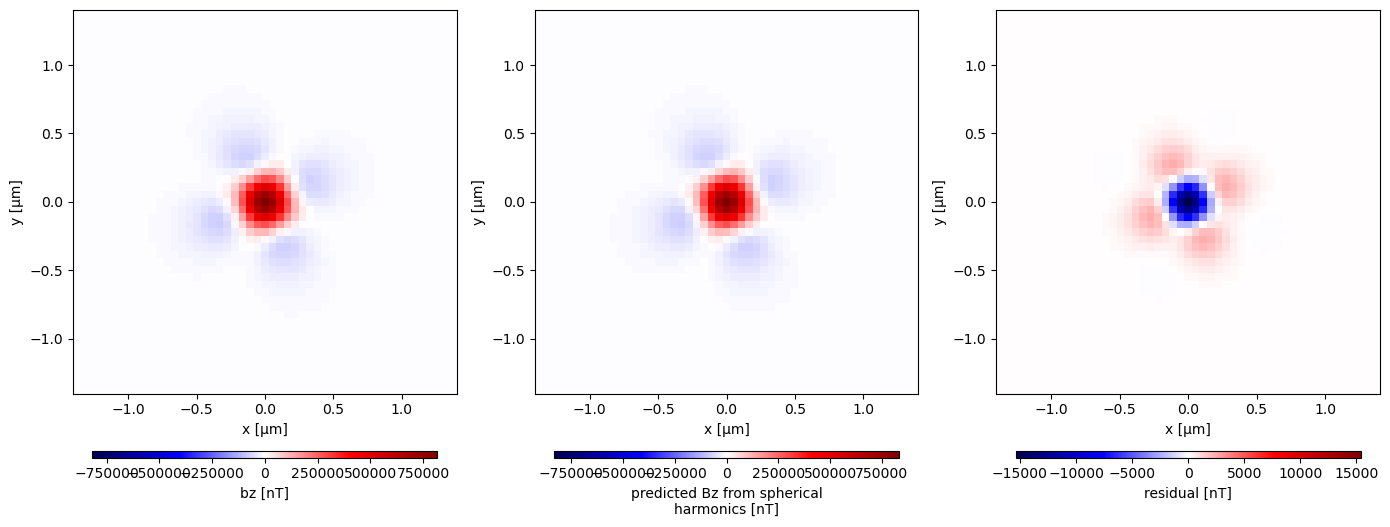

Processing model: eps12 at height 0.35 µm


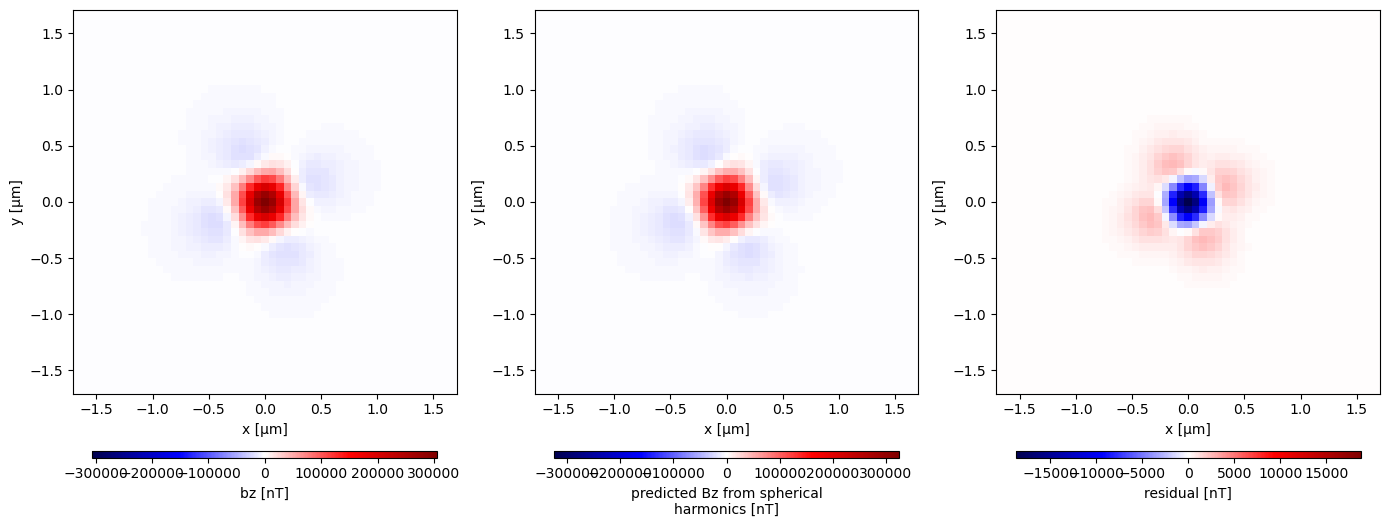

Processing model: eps12 at height 0.5 µm


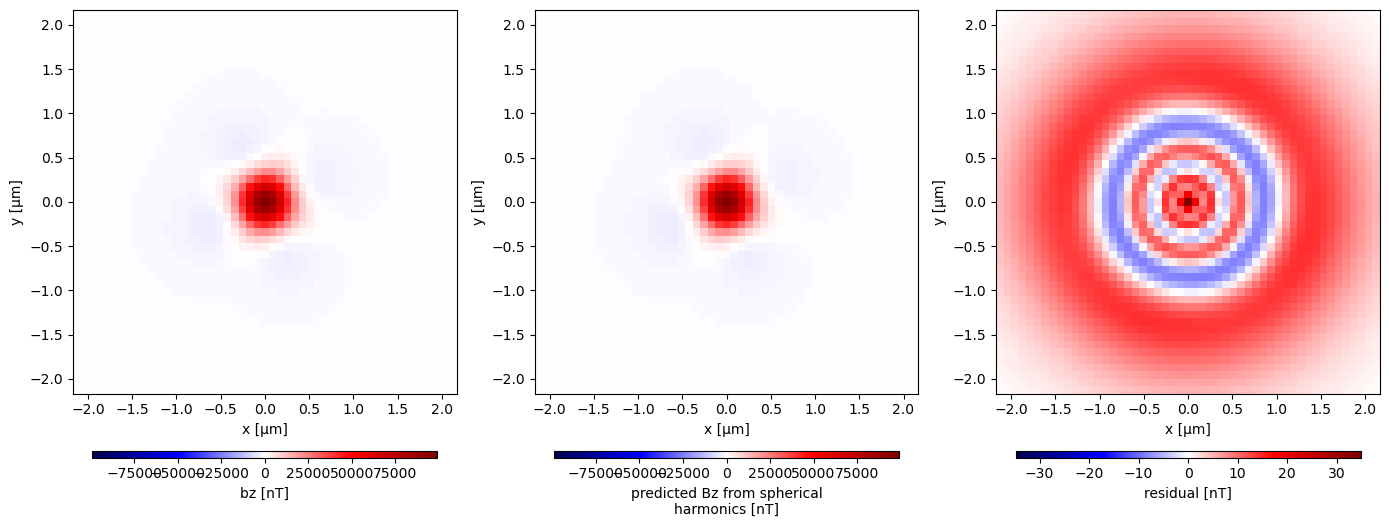

Processing model: eps12 at height 0.75 µm


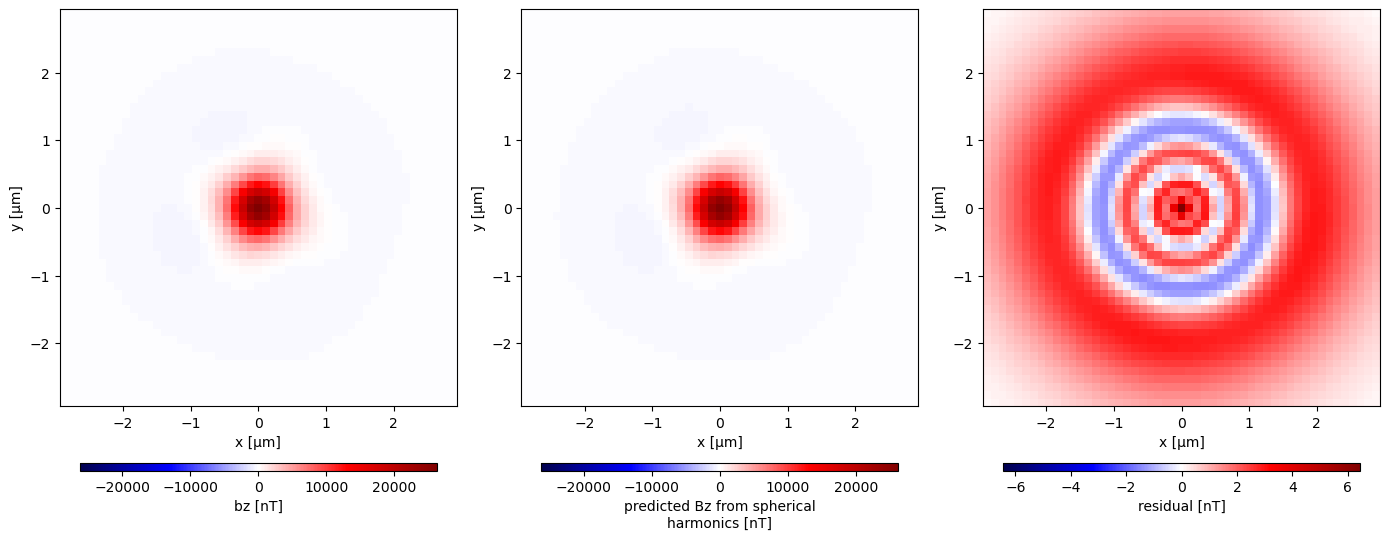

Processing model: eps12 at height 1.0 µm


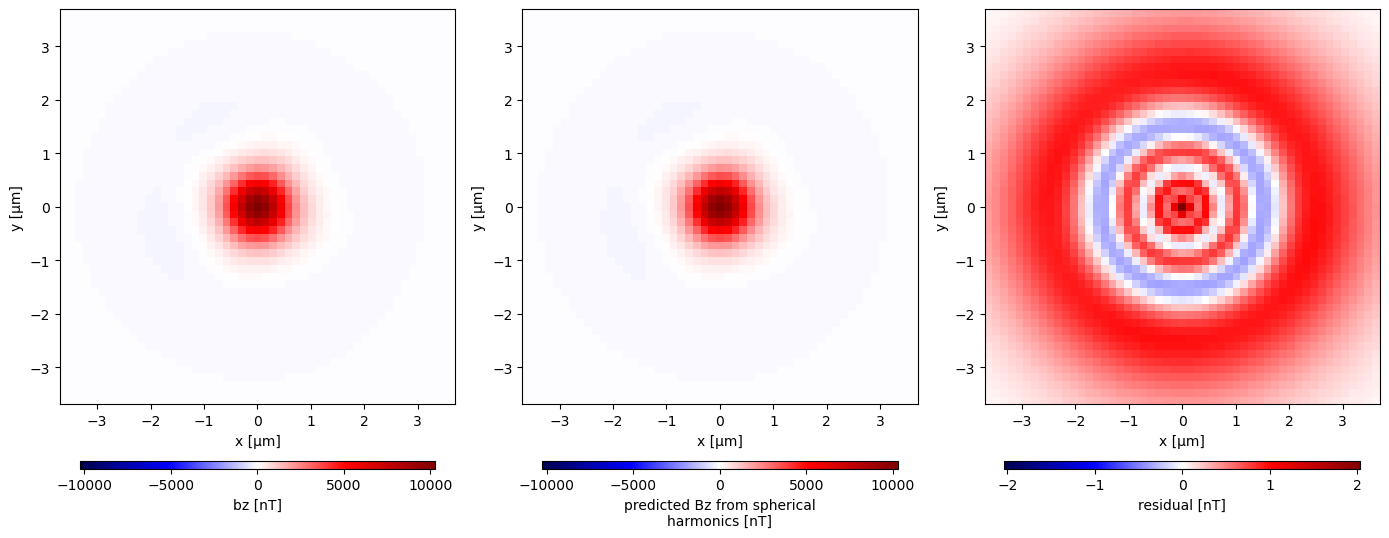

Processing model: eps12 at height 1.25 µm


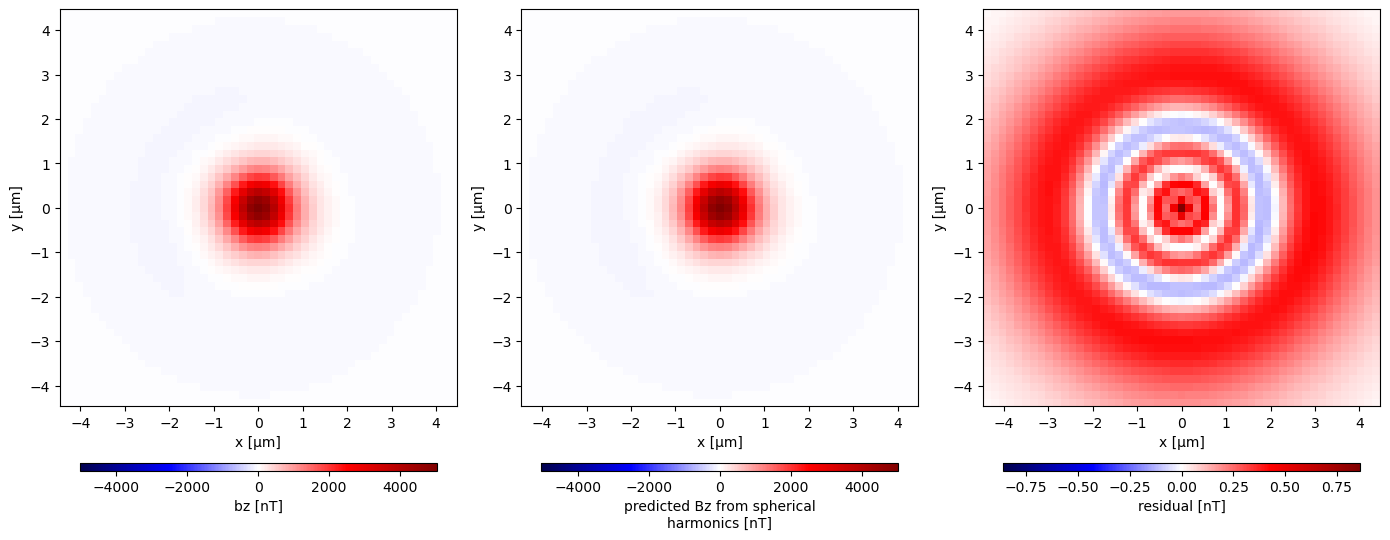

Processing model: eps12 at height 1.5 µm


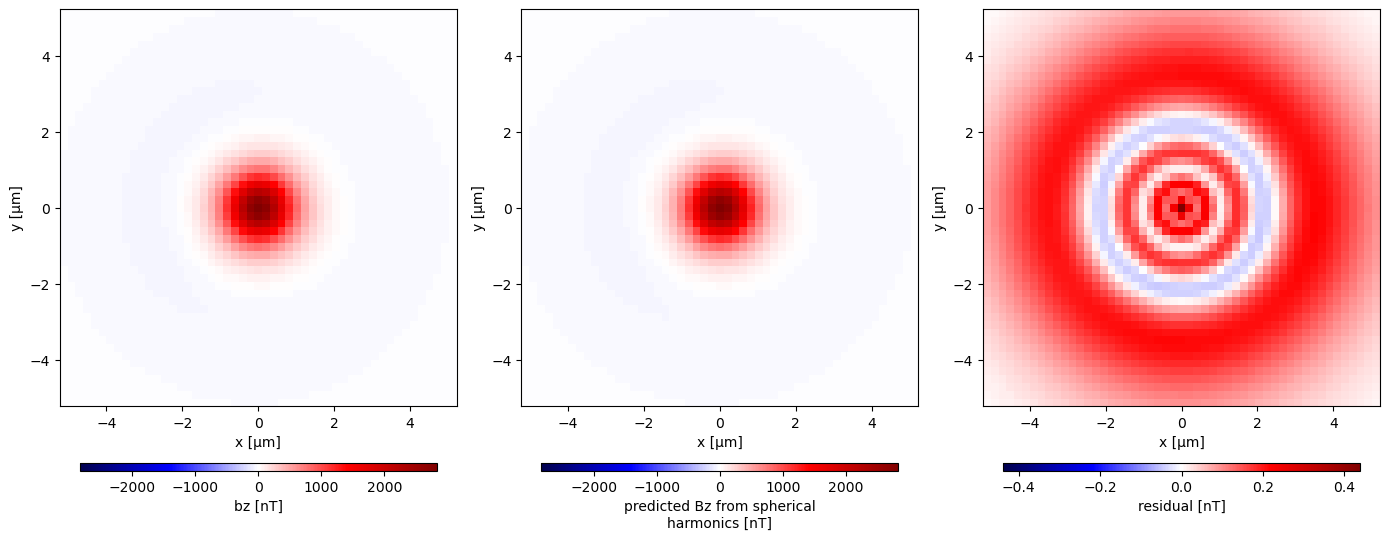

Processing model: eps12 at height 10.0 µm


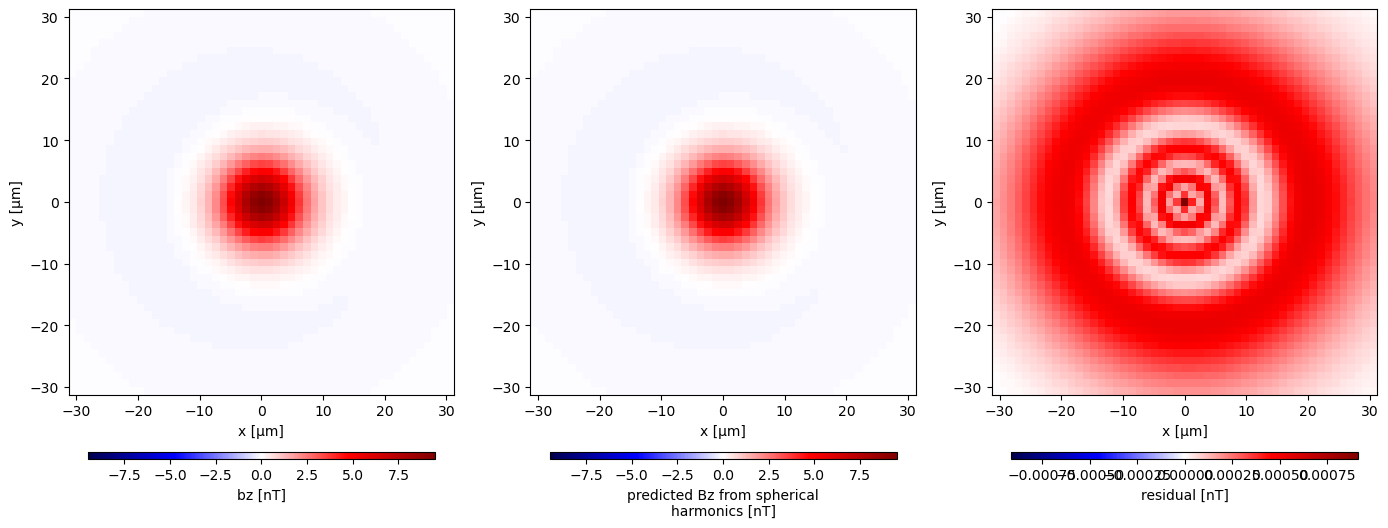

Processing model: eps12 at height 2.0 µm


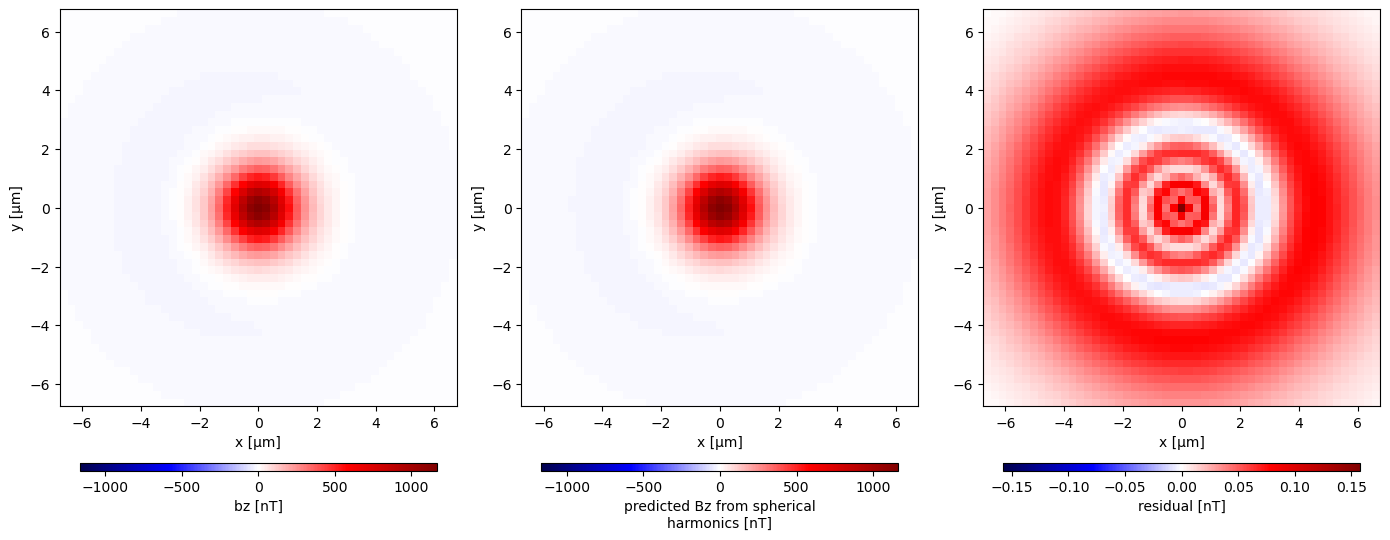

Processing model: eps12 at height 3.0 µm


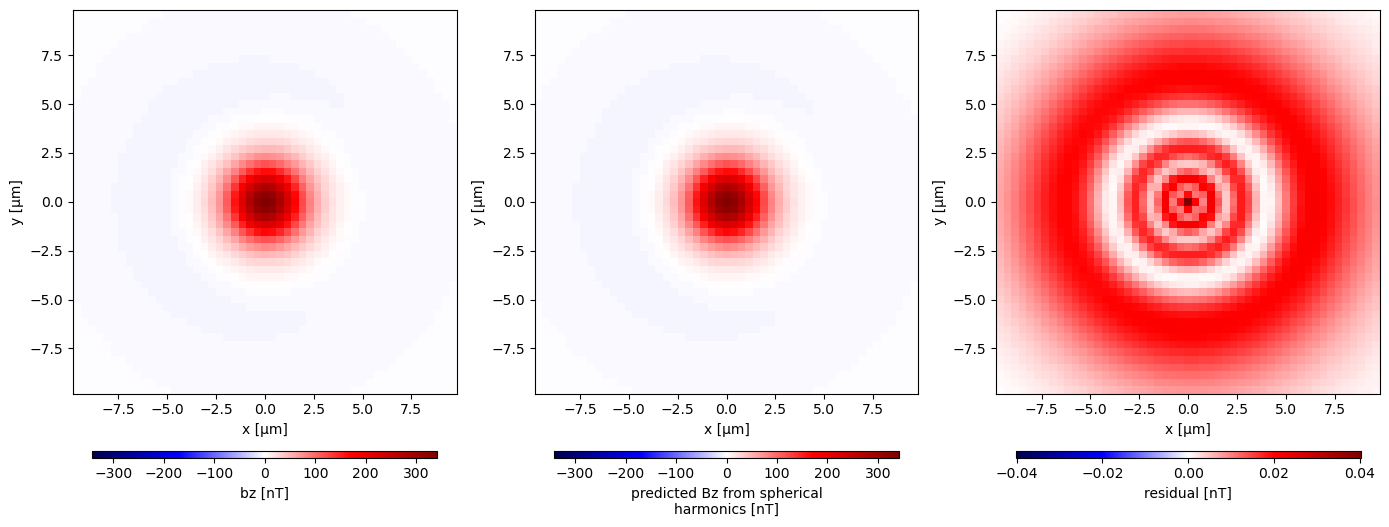

Processing model: eps12 at height 4.0 µm


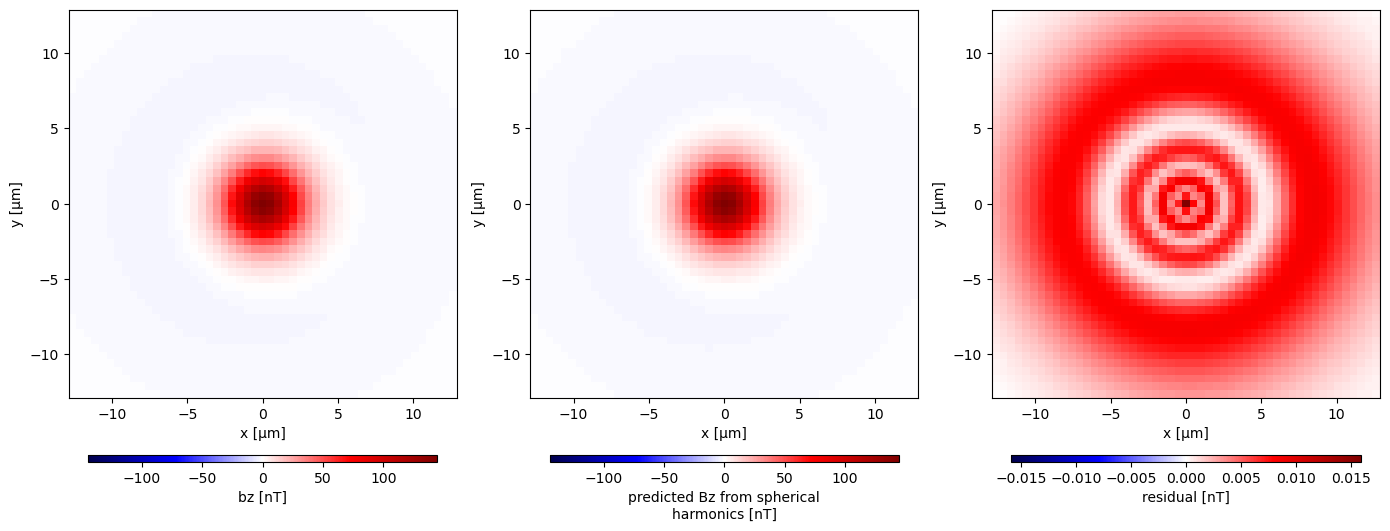

Processing model: eps12 at height 5.0 µm


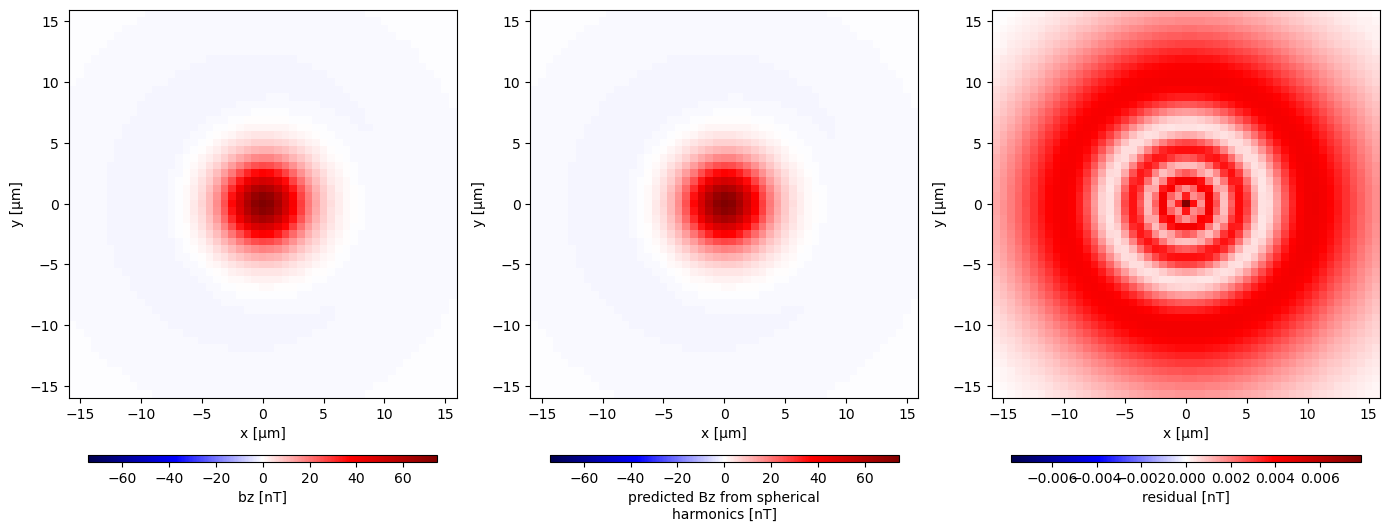

Processing model: eps12 at height 7.0 µm


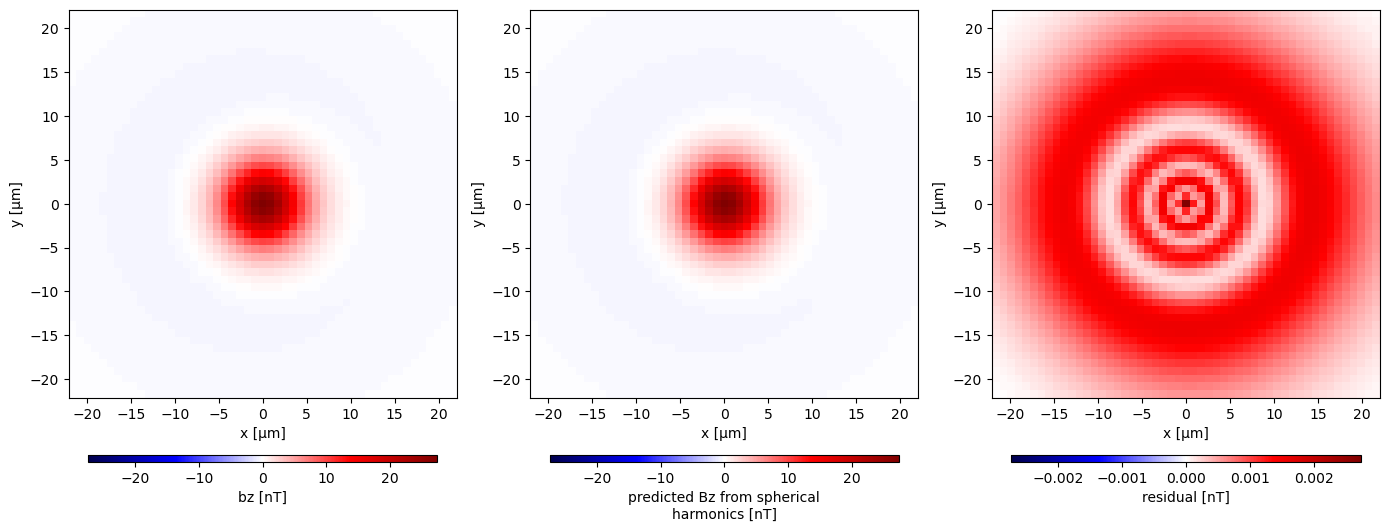

Processing model: eps17 at height 0.05 µm


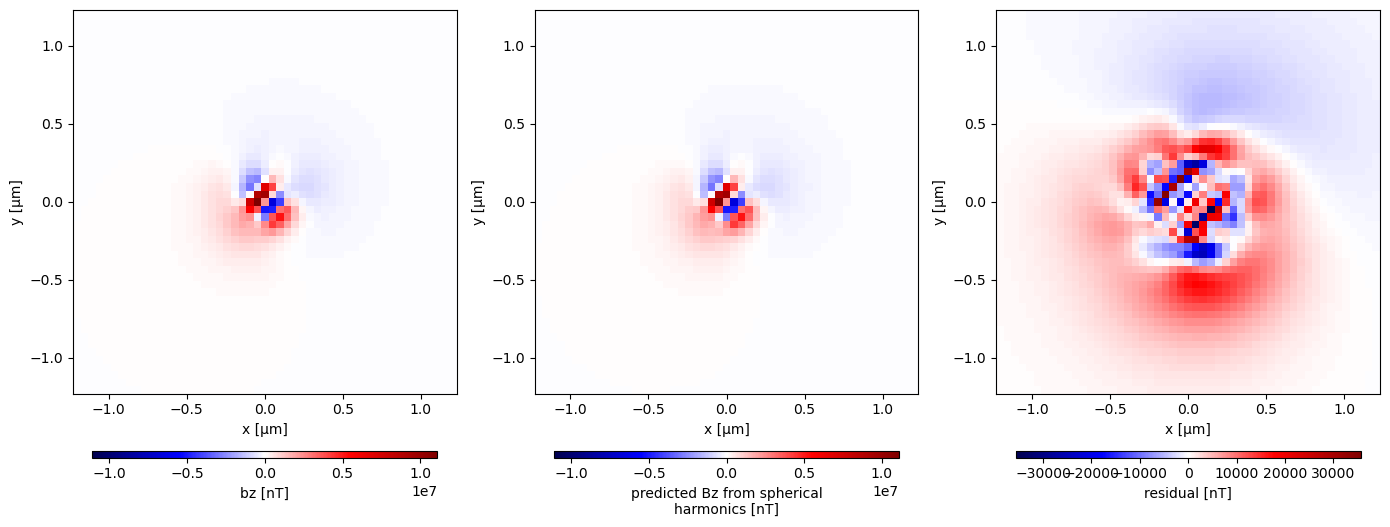

Processing model: eps17 at height 0.075 µm


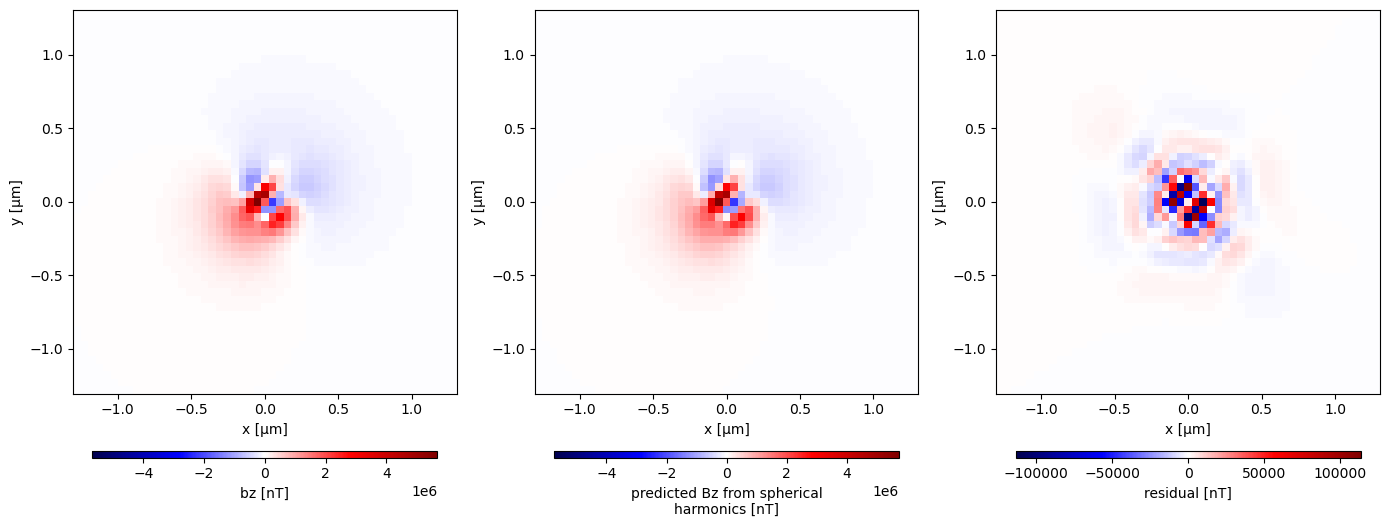

Processing model: eps17 at height 0.1 µm


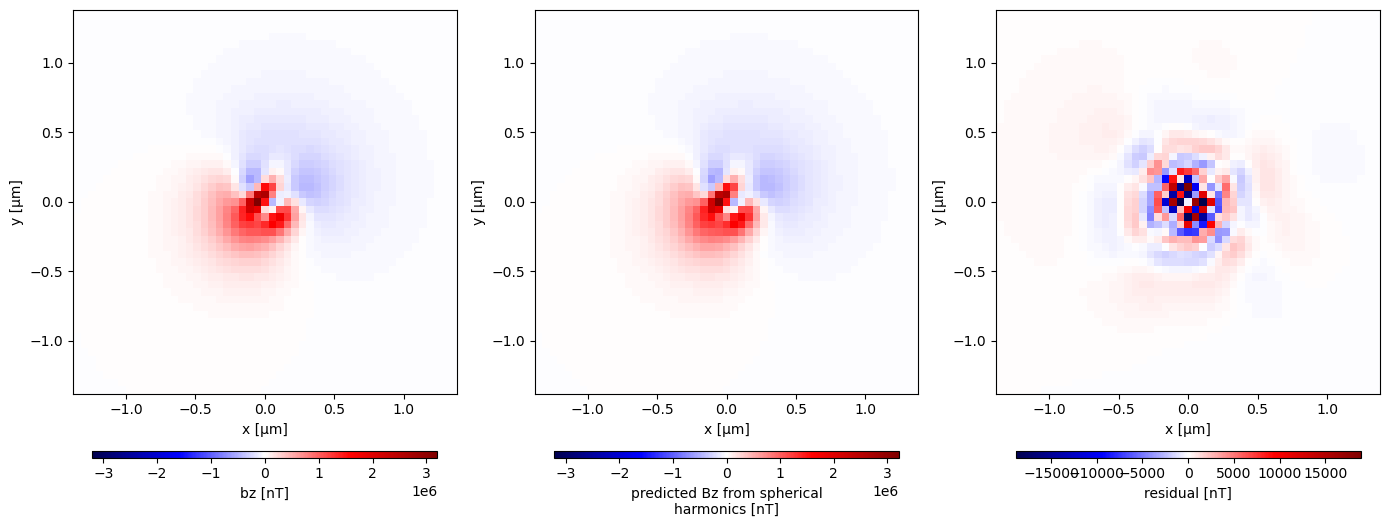

Processing model: eps17 at height 0.15 µm


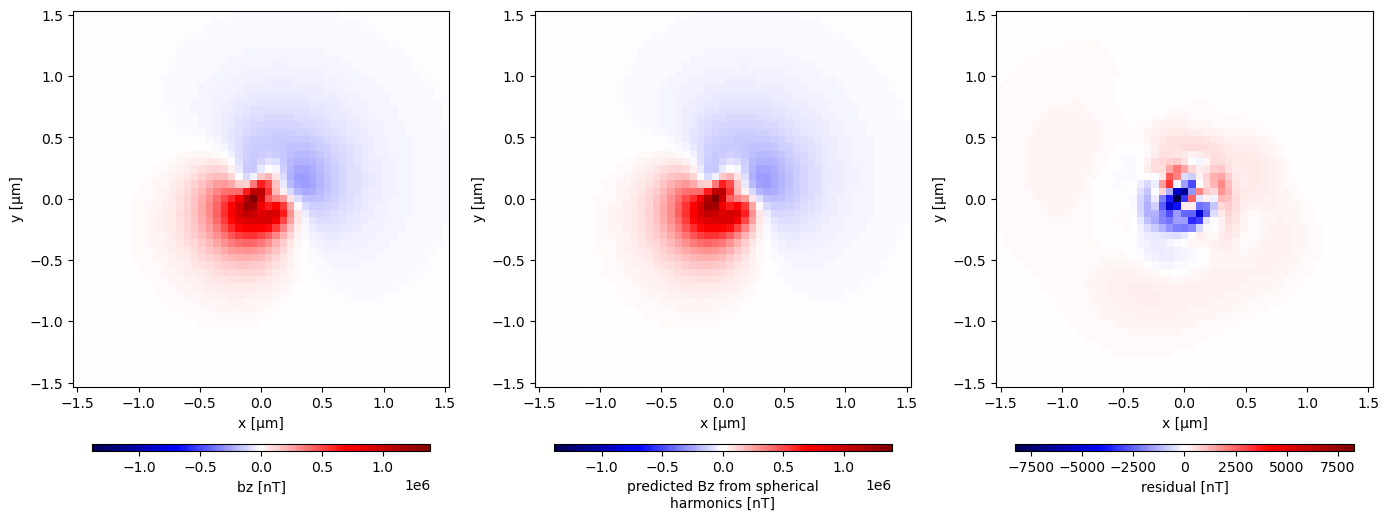

Processing model: eps17 at height 0.2 µm


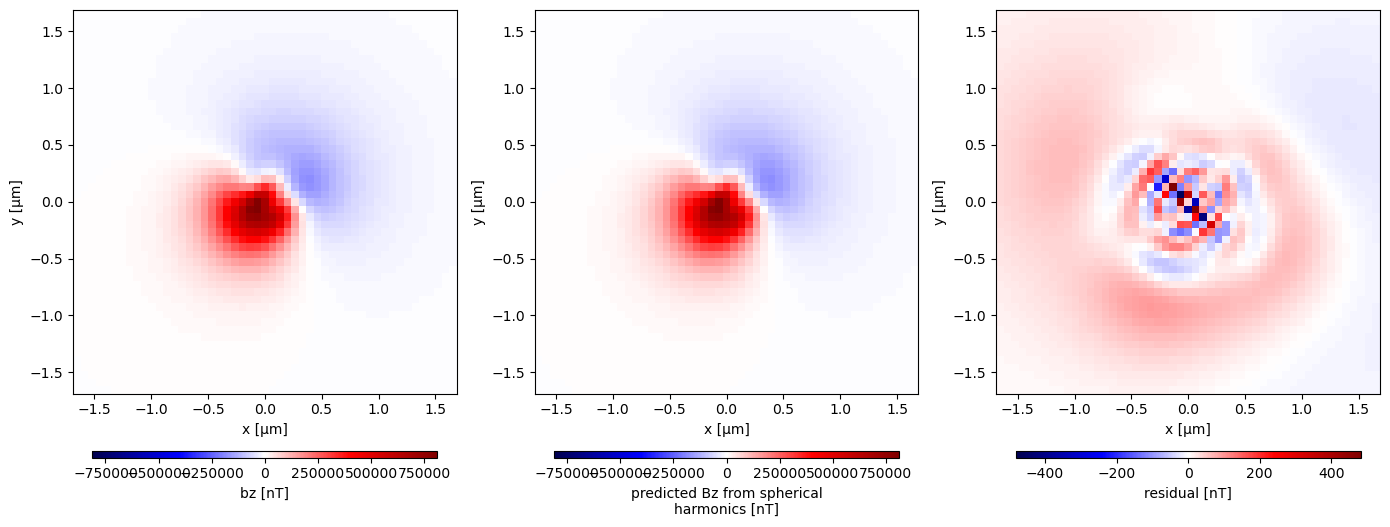

Processing model: eps17 at height 0.25 µm


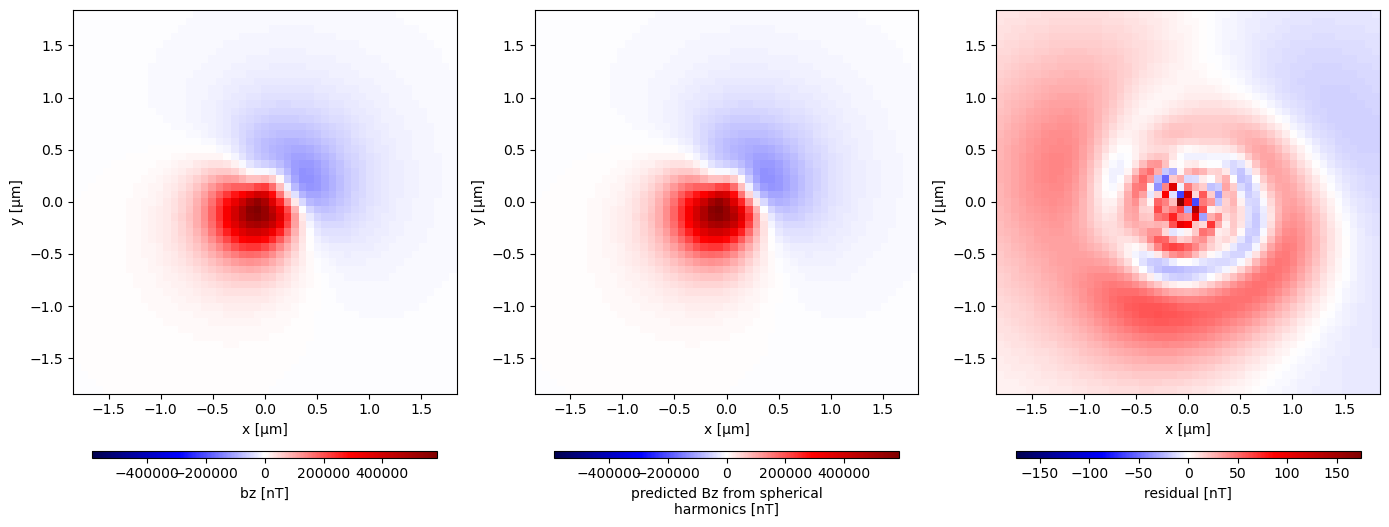

Processing model: eps17 at height 0.35 µm


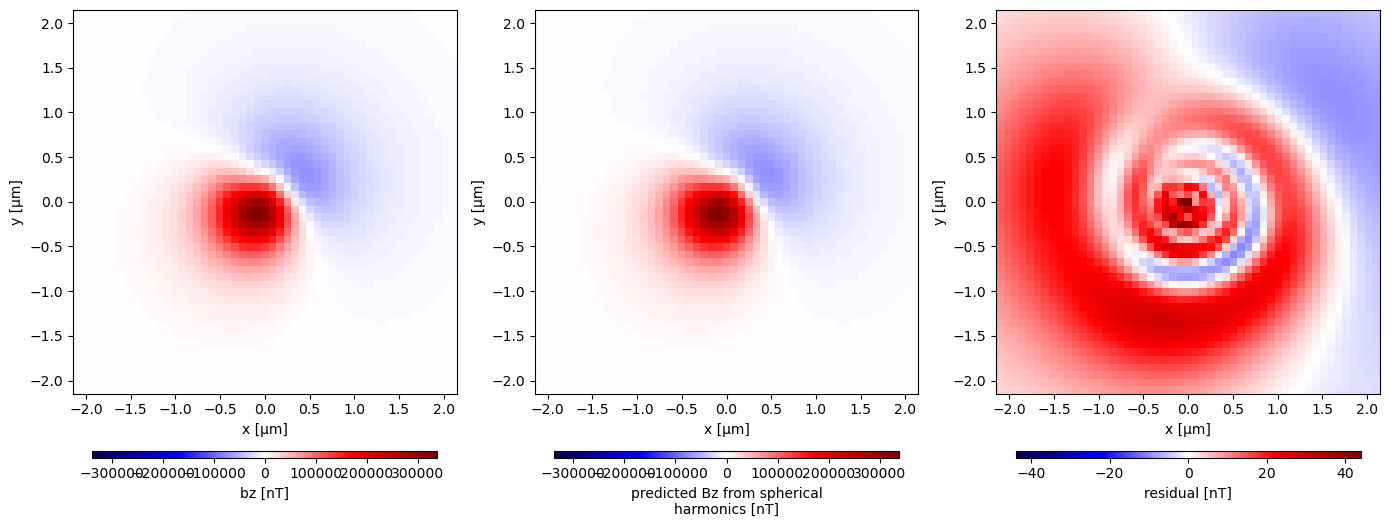

Processing model: eps17 at height 0.5 µm


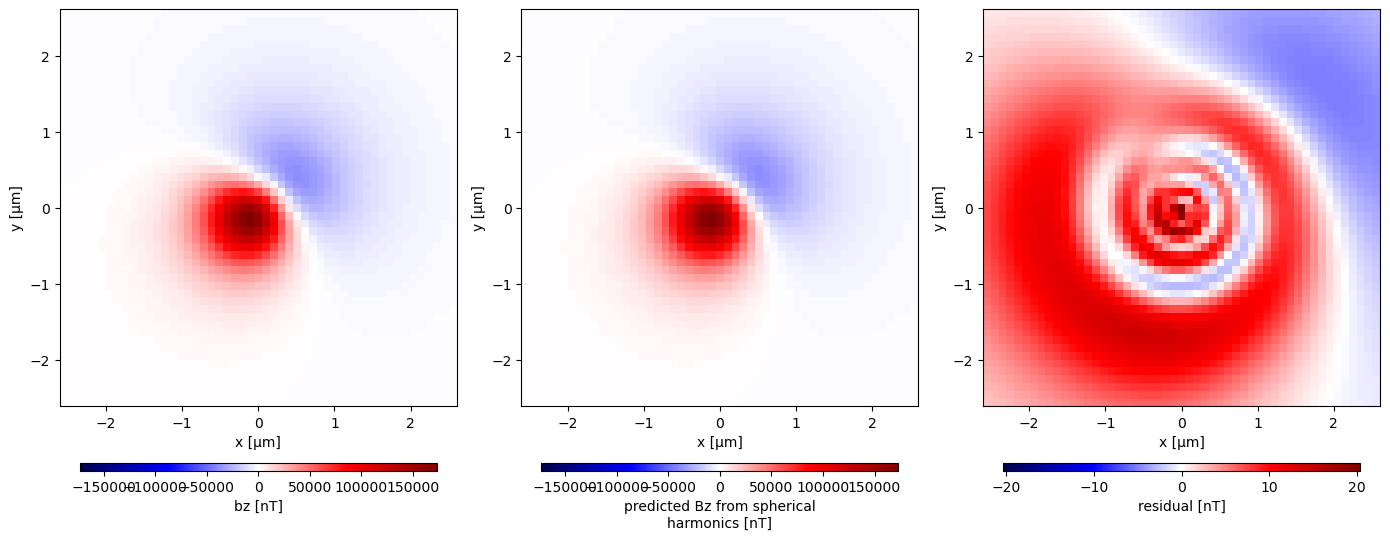

Processing model: eps17 at height 0.75 µm


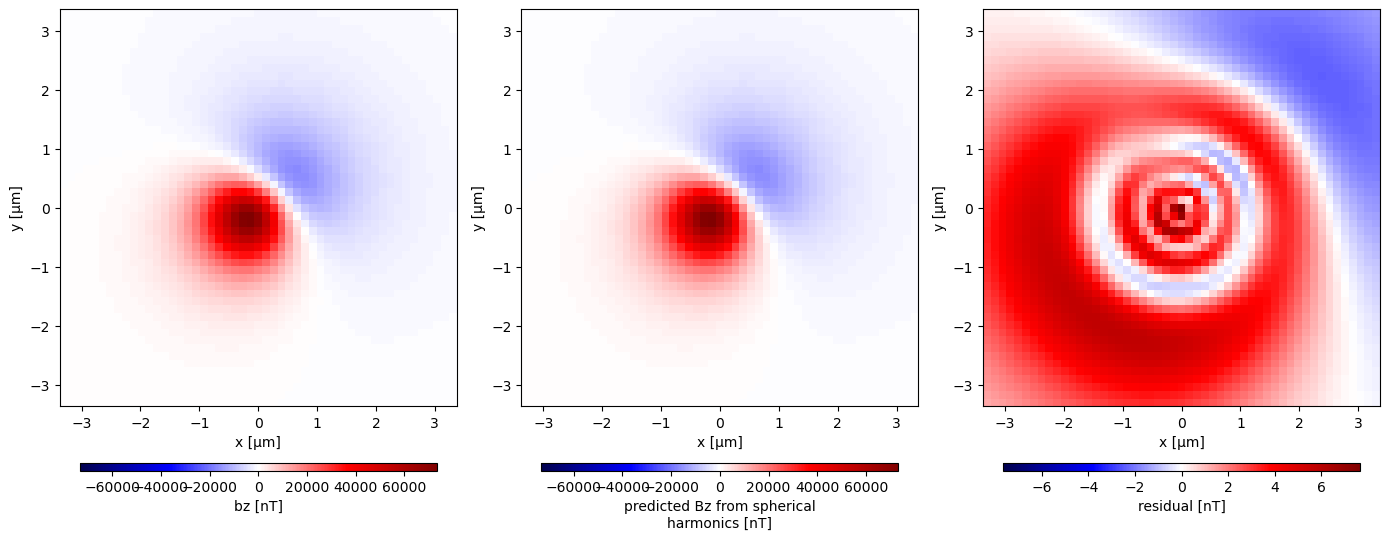

Processing model: eps17 at height 1.0 µm


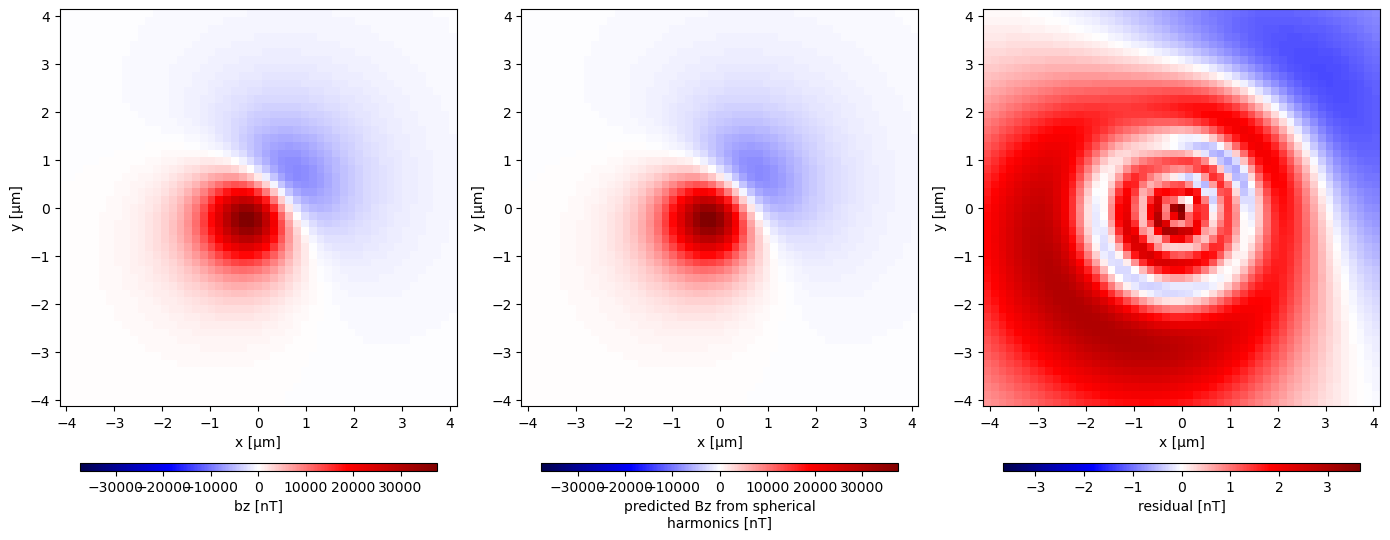

Processing model: eps17 at height 1.25 µm


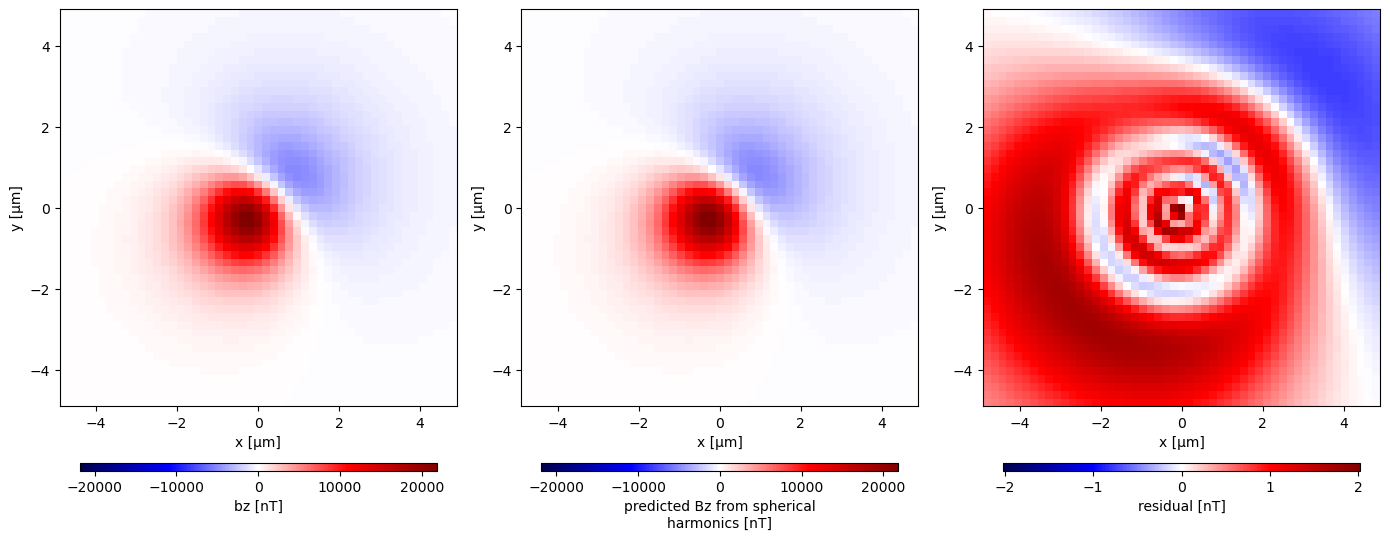

Processing model: eps17 at height 1.5 µm


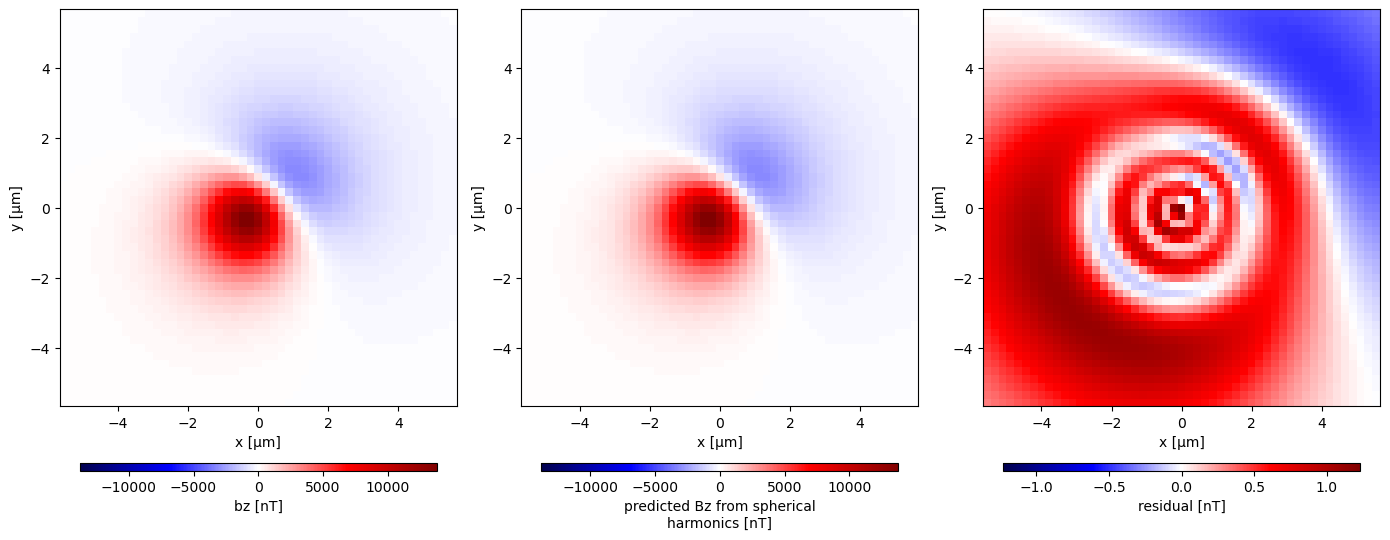

Processing model: eps17 at height 10.0 µm


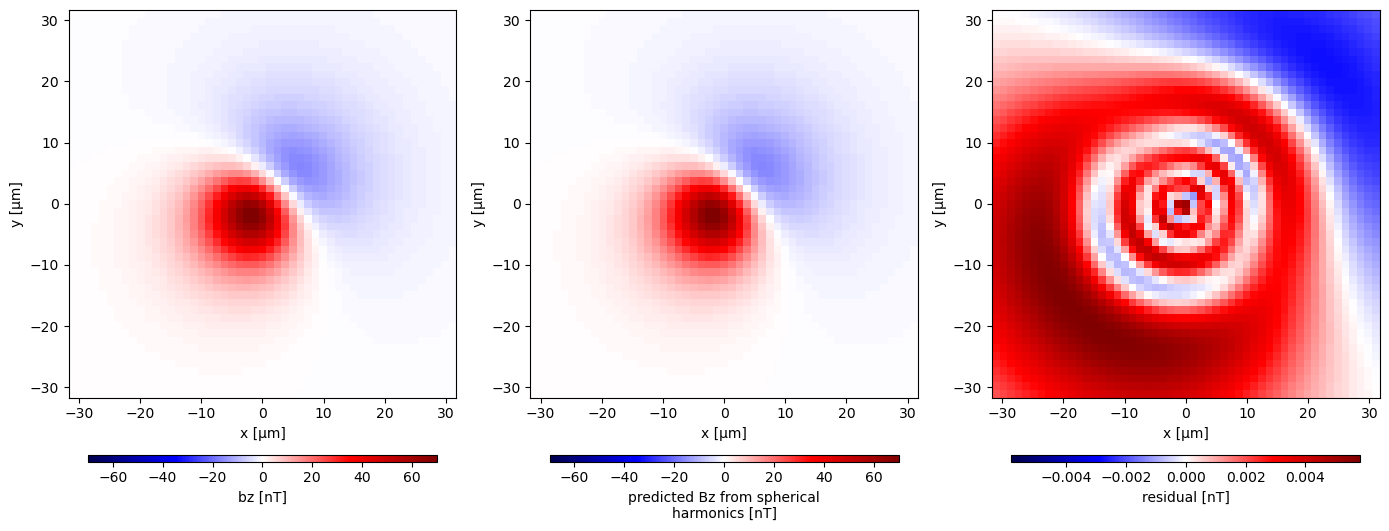

Processing model: eps17 at height 2.0 µm


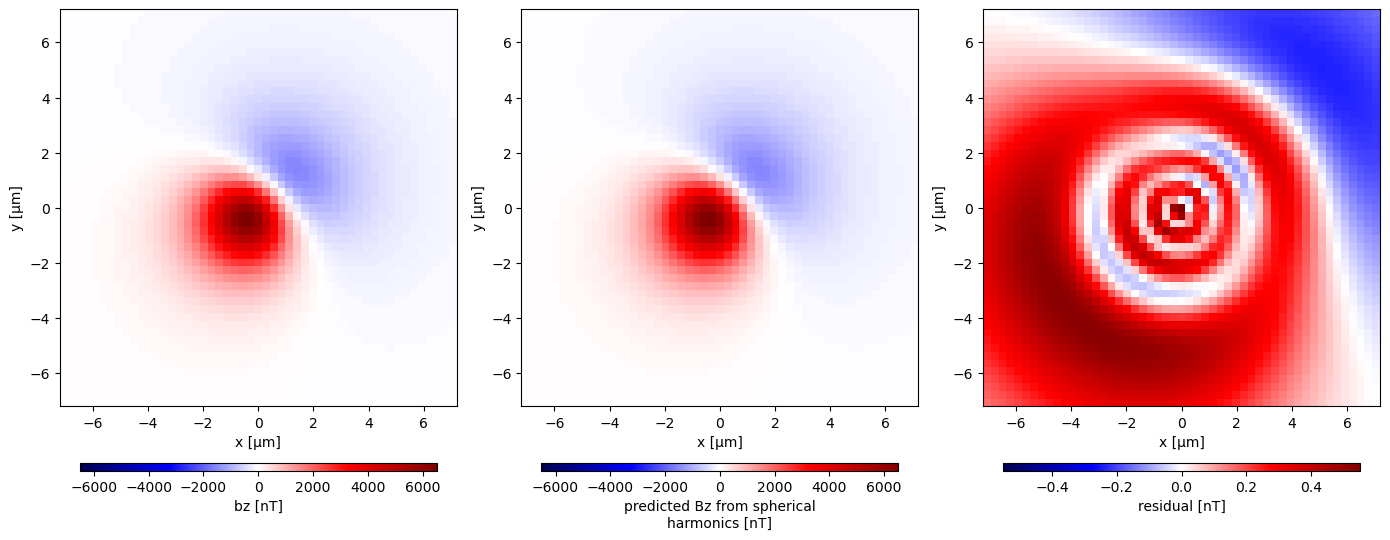

Processing model: eps17 at height 3.0 µm


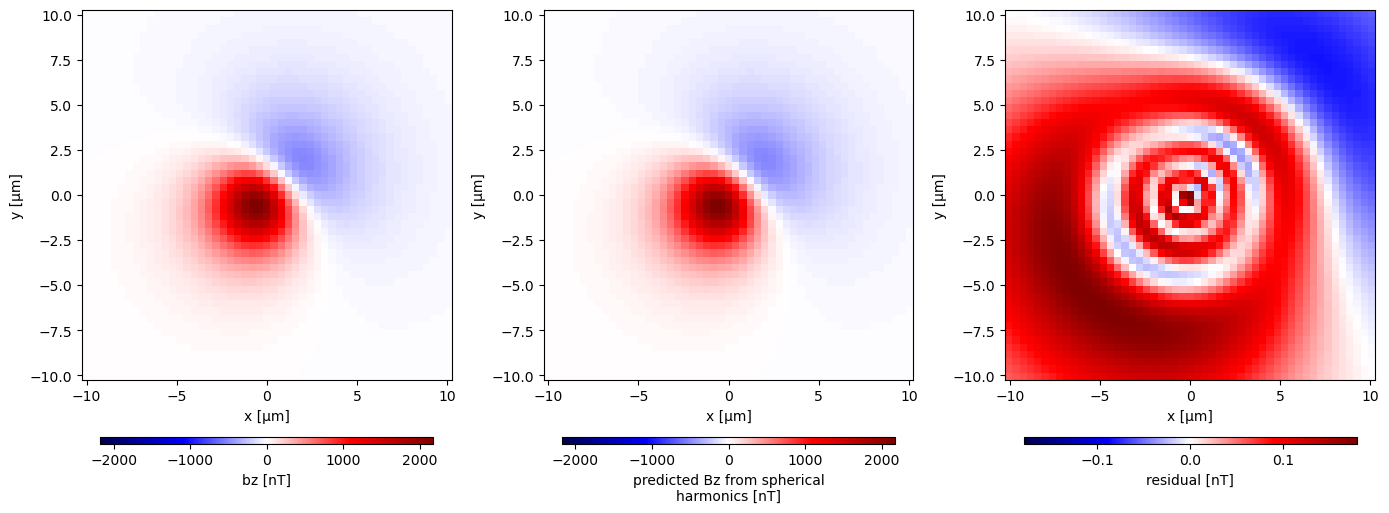

Processing model: eps17 at height 4.0 µm


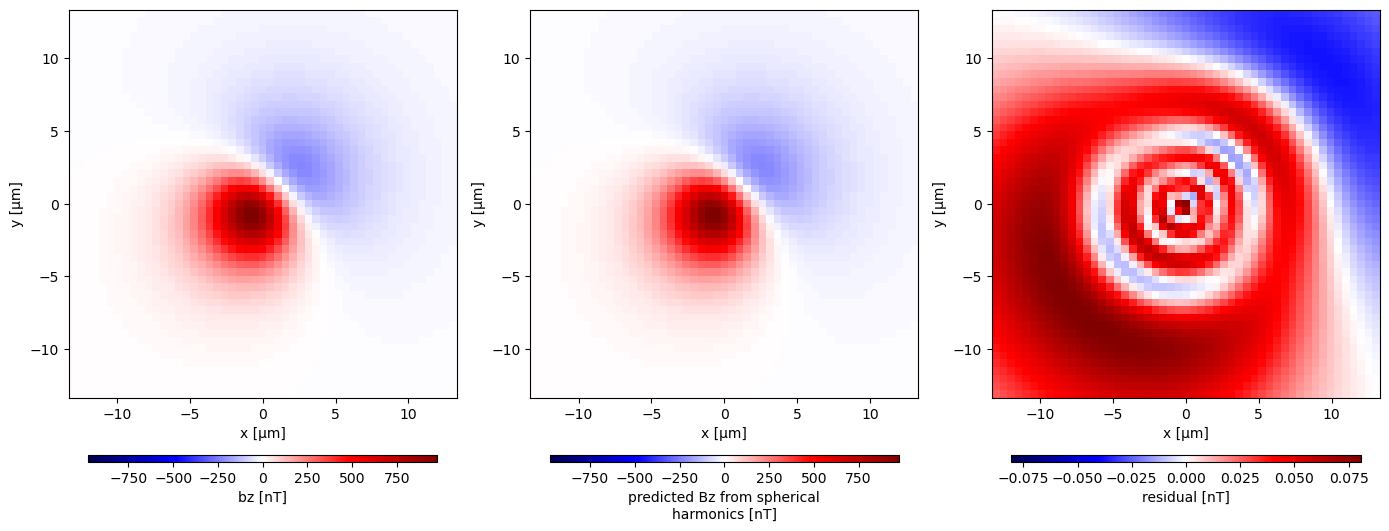

Processing model: eps17 at height 5.0 µm


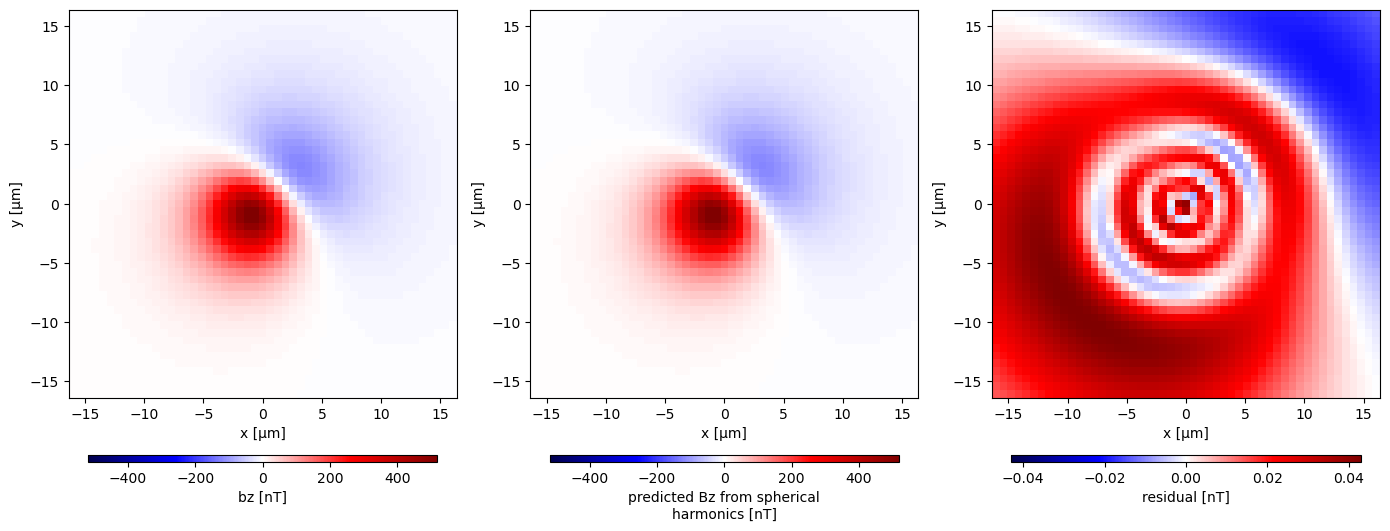

Processing model: eps17 at height 7.0 µm


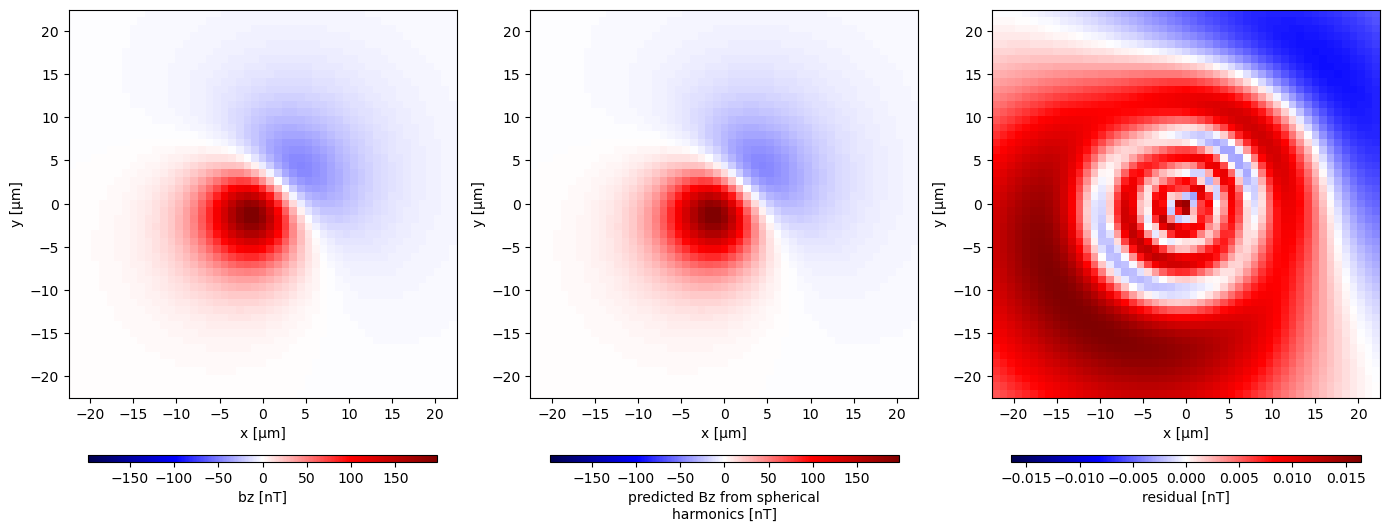

In [10]:
show_only = ["eps12", "eps17"]
for file in grid_files:
    model_name = file.stem.split("_")[1]  # e.g., "eps3"
    height = float(file.stem.split("_")[2].replace("um", ""))

    if model_name not in show_only:
        continue  # skip sources

    print(f"Processing model: {model_name} at height {height} µm")

    # read .nc file 
    ds = xr.load_dataset(file)

    data = ds[['bz']].assign_coords(
        x=ds.x,
        y=ds.y,
        z=ds.z
    )

    data_table = vd.grid_to_table(data)
    coordinates = (data_table.x, data_table.y, data_table.z)

    location = ds.centroid.values
    sph = mt.SphericalHarmonicsBz(location, damping=1e-1, min_degree=1, max_degree=10).fit(coordinates, data.bz)
    sph.update_location(coordinates, data_table)

    #predic bz
    bz_pred = sph.predict(coordinates)

    data = data.assign(bz_sph=(["y", "x"], np.reshape(bz_pred, np.shape(data.bz))))
    data.bz_sph.attrs = {"long_name": "predicted Bz from spherical harmonics", "units": "nT"}

    residual = data.bz.values - data.bz_sph.values
    data = data.assign(residual_sph=(["y", "x"], residual))
    data.residual_sph.attrs = {"long_name": "residual", "units": "nT"}


    fig, axes = plt.subplots(1, 3, figsize=(14, 6))
    cbar_kwargs = dict(orientation="horizontal", aspect=50, pad=0.1, shrink=0.9)
    for field, ax in zip(["bz", "bz_sph", "residual_sph"], axes.ravel()):
        vmax = None
        vmin = None
        data[field].plot.pcolormesh(ax=ax, cmap="seismic", cbar_kwargs=cbar_kwargs, vmax=vmax, vmin=vmin)
    for ax in axes.ravel():
        ax.set_aspect("equal")
    plt.tight_layout()
    plt.show()